Dataset Shape: (30, 2)

First Five Rows:
   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0

Dataset Description:
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000

Missing Values:
YearsExperience    0
Salary             0
dtype: int64

 Linear Regression
MAE: 3426.4269374307078
MSE: 21026037.329511296
RMSE: 4585.4157204675885
R2 Score: 0.9749154407708353

 Polynomial Regression
MAE: 3562.939035525857
MSE: 21559299.688830055
RMSE: 4643.199294541432
R2 Score: 0.9742792461789879

Model Comparison:
                   Model          MAE           MSE         RMSE  R2 Score
0      Linear R

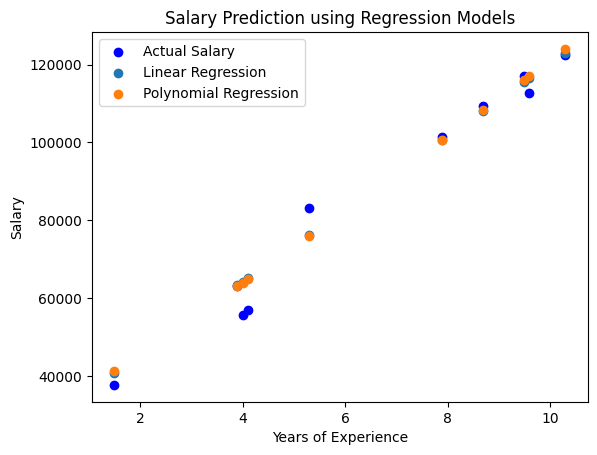

In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline


data = pd.read_csv("Salary_Data.csv")

print("Dataset Shape:", data.shape)
print("\nFirst Five Rows:")
print(data.head())

print("\nDataset Description:")
print(data.describe())

print("\nMissing Values:")
print(data.isnull().sum())

# 2. Select input and output
X = data[['YearsExperience']]
y = data['Salary']

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=2/3, random_state=0
)

# 4. Create regression models
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression": make_pipeline(
        PolynomialFeatures(degree=2),
        LinearRegression()
    )
}

results = []

# 5. Train and evaluate models
for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append([name, mae, mse, rmse, r2])

    print("\n", name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

# 6. Compare model performance
result_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

print("\nModel Comparison:")
print(result_df)

# 7. Plot actual and predicted values
plt.scatter(X_test, y_test, color='blue', label='Actual Salary')

for name, model in models.items():
    plt.scatter(
        X_test, model.predict(X_test),
        label=name
    )

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary Prediction using Regression Models")
plt.legend()
plt.show()
